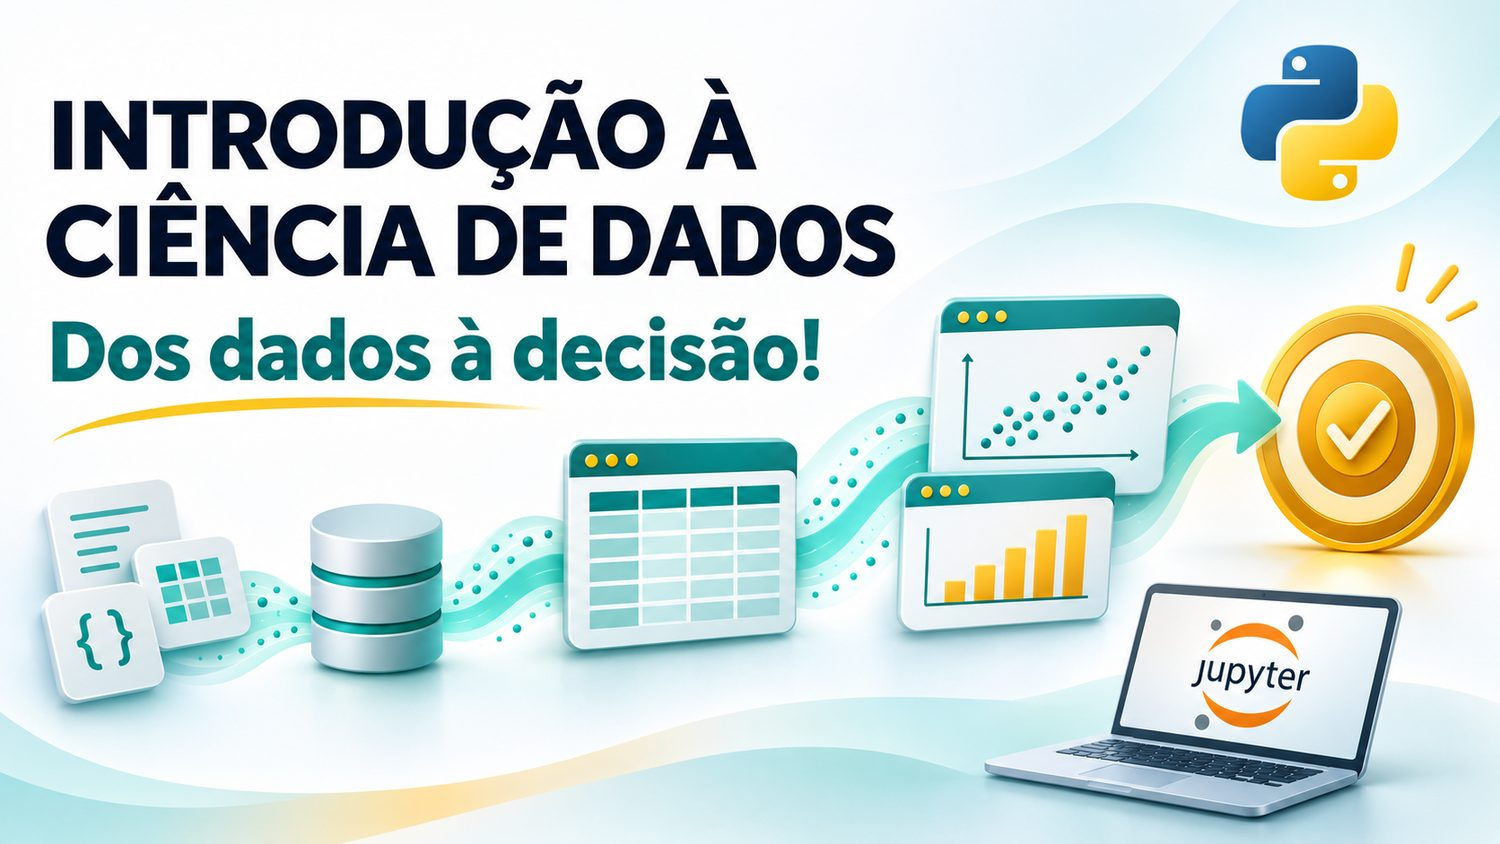

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/projeto_dados_reais/01_Enquadrar_e_Auditar_os_Dados.ipynb)

# Projeto com dados reais · Parte 1 – Enquadrar o problema e auditar os dados

Até aqui, todos os dados do tutorial foram sintéticos: gerados por uma função, com os defeitos que convinha mostrar em cada capítulo. Este projeto usa **dados reais**: mais de 41 000 chamadas de campanhas de telemarketing de um banco português, feitas entre 2008 e 2010, para vender depósitos a prazo.

Com dados reais ninguém te diz onde estão os problemas, a documentação tem lacunas e há perguntas que ficam sem resposta. O projeto tem três partes, e esta é a primeira: antes de qualquer modelo, perceber de onde vêm os dados, o que significam e em que é que não se pode confiar.

> **Objetivos:** avaliar uma fonte de dados real; escrever o enquadramento do problema; ler o ficheiro e construir o dicionário de dados; encontrar valores em falta disfarçados; reconstruir a ordem temporal a partir da documentação; decidir que colunas se podem usar no momento da previsão; registar as decisões numa função reutilizável.

**Pré-requisitos:** módulo 1 (capítulos 2 e 4), módulo 2 (capítulos 1 a 4) e módulo 4 (capítulo 3).

**Duração sugerida:** 2 horas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## A fonte

O conjunto de dados chama-se *Bank Marketing* e está publicado no UCI Machine Learning Repository. Antes de o abrir, aplicam-se as cinco verificações do módulo 2 (capítulo 1):

| Verificação | O que se sabe |
| --- | --- |
| **Proveniência** | Registos de um banco de retalho português, reunidos por S. Moro, P. Cortez e P. Rita para um artigo científico de 2014. O nome do banco não é indicado. |
| **Cobertura** | Clientes a quem o banco **telefonou** em campanhas de depósitos a prazo, de maio de 2008 a novembro de 2010. Quem não foi contactado não aparece. |
| **Documentação** | Um ficheiro de texto descreve as 21 colunas. Não explica como os clientes eram escolhidos, nem o que mudou de campanha para campanha. |
| **Atualidade** | Os dados têm mais de quinze anos e apanham a crise financeira de 2008. Servem para aprender, não para decidir hoje. |
| **Uso permitido** | Licença Creative Commons Atribuição 4.0 (CC BY 4.0): pode ser usado e adaptado, desde que se cite a fonte. |

A documentação acrescenta um aviso importante: o ficheiro é «quase idêntico» ao do artigo, porque **alguns atributos foram retirados por motivos de privacidade**. Trabalhas, portanto, com menos informação do que o banco tinha.

> **Citação:** S. Moro, P. Cortez e P. Rita (2014). *A Data-Driven Approach to Predict the Success of Bank Telemarketing*. Decision Support Systems, 62, 22–31. Dados: *Bank Marketing*, UCI Machine Learning Repository, https://doi.org/10.24432/C5K306 (CC BY 4.0).

## O enquadramento

Imagina que trabalhas na equipa de dados do banco no final de 2009. A direção comercial vai continuar as campanhas em 2010 e pede ajuda. A ficha de enquadramento (módulo 1, capítulo 6) fica assim:

| Componente | Neste projeto |
| --- | --- |
| **Problema** | Cada chamada custa tempo de um operador, e a maior parte não dá em subscrição. |
| **Pergunta analítica** | Dada uma lista de clientes a contactar, por que ordem se deve telefonar para apanhar o maior número de subscrições? |
| **Partes interessadas** | Direção comercial (decide), operadores do centro de contacto (usam a lista), clientes (recebem as chamadas). |
| **Decisão** | A equipa só consegue telefonar a **20% da lista** de cada campanha. A quem? |
| **Dados necessários** | Uma linha por chamada: quem é o cliente, que contactos já houve, e se subscreveu. |
| **Abordagem** | Prever (ordenar os clientes por probabilidade de subscrição) para decidir (os primeiros 20%). |
| **Riscos e limitações** | Só há dados de quem foi contactado; as campanhas mudaram ao longo do tempo; dados pessoais de clientes. |
| **Critérios de sucesso** | Subscrições apanhadas ao telefonar a 20% da lista, comparadas com telefonar ao acaso e com uma regra simples, em campanhas **posteriores** às usadas para aprender. |

O **momento da previsão** é o instante antes de marcar o número. Tudo o que só se sabe depois de a chamada começar fica de fora.

## Ler o ficheiro

O ficheiro está na pasta `dados/` do projeto. Se abriste o notebook no Colab, essa pasta não existe e o ficheiro é lido diretamente do repositório do tutorial.

In [2]:
import os

FICHEIRO = "dados/bank-additional-full.csv"
ENDERECO = ("https://raw.githubusercontent.com/ricardoluizdasilva/mestrado_ai_estudos/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20"
            "Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/projeto_dados_reais/" + FICHEIRO)
origem = FICHEIRO if os.path.exists(FICHEIRO) else ENDERECO

pd.read_csv(origem, nrows=3)

,"age;""job"";""marital"";""education"";""default"";""housing"";""loan"";""contact"";""month"";""day_of_week"";""duration"";""campaign"";""pdays"";""previous"";""poutcome"";""emp.var.rate"";""cons.price.idx"";""cons.conf.idx"";""euribor3m"";""nr.employed"";""y"""
0,"56;""housemaid"";""married"";""basic.4y"";""no"";""no"";..."
1,"57;""services"";""married"";""high.school"";""unknown..."
2,"37;""services"";""married"";""high.school"";""no"";""ye..."


Três linhas e **uma só coluna**, com tudo lá dentro. O separador não é a vírgula: é o ponto e vírgula (módulo 2, capítulo 3). É o primeiro sinal de que um ficheiro real não se lê às cegas.

In [3]:
bruto = pd.read_csv(origem, sep=";")
print(bruto.shape)
bruto.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


41 188 linhas e 21 colunas, como diz a documentação. Confirmar as dimensões contra a documentação é uma verificação barata de que o ficheiro é o certo e chegou inteiro.

## O dicionário de dados

A tabela junta o que a documentação diz de cada coluna. Os nomes originais estão em inglês abreviado; para trabalhar, passam a nomes em português. A última coluna responde à pergunta do enquadramento: **conhece-se antes da chamada?**

| Original | Nome novo | Significado | Antes da chamada? |
| --- | --- | --- | --- |
| `age` | `idade` | Idade do cliente, em anos | Sim |
| `job` | `profissao` | Tipo de profissão (12 categorias) | Sim |
| `marital` | `estado_civil` | Estado civil | Sim |
| `education` | `escolaridade` | Nível de escolaridade | Sim |
| `default` | `incumprimento` | Tem crédito em incumprimento? | Sim |
| `housing` | `credito_habitacao` | Tem crédito à habitação? | Sim |
| `loan` | `credito_pessoal` | Tem crédito pessoal? | Sim |
| `contact` | `meio_contacto` | Tipo de telefone: telemóvel (`cellular`) ou fixo (`telephone`) | Sim |
| `month` | `mes` | Mês do último contacto | Sim |
| `day_of_week` | `dia_semana` | Dia da semana do último contacto | Sim |
| `duration` | `duracao_s` | Duração da última chamada, em segundos | **Não** |
| `campaign` | `contactos_campanha` | Contactos feitos a este cliente nesta campanha, incluindo este | Sim |
| `pdays` | `dias_desde_anterior` | Dias desde o último contacto de uma campanha anterior (999 = nunca contactado) | Sim |
| `previous` | `contactos_anteriores` | Contactos feitos a este cliente antes desta campanha | Sim |
| `poutcome` | `resultado_anterior` | Resultado da campanha anterior: `success`, `failure` ou `nonexistent` | Sim |
| `emp.var.rate` | `var_emprego` | Taxa de variação do emprego (indicador trimestral) | Sim |
| `cons.price.idx` | `indice_precos` | Índice de preços no consumidor (mensal) | Sim |
| `cons.conf.idx` | `indice_confianca` | Índice de confiança dos consumidores (mensal) | Sim |
| `euribor3m` | `euribor_3m` | Taxa Euribor a três meses (diária) | Sim |
| `nr.employed` | `n_empregados` | Número de pessoas empregadas (indicador trimestral) | Sim |
| `y` | `subscreveu` | O cliente subscreveu o depósito a prazo? | É o alvo |

Os valores das categorias ficam como estão na fonte (`married`, `blue-collar`, …): traduzir valores é mais uma transformação que pode correr mal, e aqui não é precisa.

In [4]:
NOMES = {"age": "idade", "job": "profissao", "marital": "estado_civil", "education": "escolaridade", "default": "incumprimento",
         "housing": "credito_habitacao", "loan": "credito_pessoal", "contact": "meio_contacto", "month": "mes",
         "day_of_week": "dia_semana", "duration": "duracao_s", "campaign": "contactos_campanha", "pdays": "dias_desde_anterior",
         "previous": "contactos_anteriores", "poutcome": "resultado_anterior", "emp.var.rate": "var_emprego",
         "cons.price.idx": "indice_precos", "cons.conf.idx": "indice_confianca", "euribor3m": "euribor_3m",
         "nr.employed": "n_empregados", "y": "subscreveu"}

dados = bruto.rename(columns=NOMES)
dados["subscreveu"].value_counts(normalize=True).round(4)

subscreveu
no     0.8873
yes    0.1127
Name: proportion, dtype: float64

Cerca de 11% das chamadas acabaram em subscrição. É a taxa de base de todo o ficheiro; mais à frente vais ver que este número esconde quase tudo o que interessa.

## Auditoria

O módulo 2 (capítulo 4) organizou os problemas de qualidade em cinco famílias: consistência, completude, validade, duplicação e enviesamento. Segue-se a mesma ordem, começando pelo primeiro olhar.

In [5]:
resumo = pd.DataFrame({"tipo": dados.dtypes.astype(str), "em_falta": dados.isna().sum(), "valores_distintos": dados.nunique()})
resumo

,tipo,em_falta,valores_distintos
idade,int64,0,78
profissao,str,0,12
estado_civil,str,0,4
escolaridade,str,0,8
incumprimento,str,0,3
credito_habitacao,str,0,3
credito_pessoal,str,0,3
meio_contacto,str,0,2
mes,str,0,10
dia_semana,str,0,5


Zero valores em falta em todas as colunas. Num ficheiro real com 41 000 linhas preenchidas à mão e por sistemas, isso é suspeito: o mais provável é que a falta esteja **escrita de outra maneira**.

### Completude: os valores em falta disfarçados

Nas colunas de texto, a documentação usa a categoria `unknown`.

In [6]:
texto = [c for c in dados.columns if not pd.api.types.is_numeric_dtype(dados[c]) and c != "subscreveu"]
desconhecidos = pd.DataFrame({"unknown": [(dados[c] == "unknown").sum() for c in texto]}, index=texto)
desconhecidos["percentagem"] = (100 * desconhecidos["unknown"] / len(dados)).round(1)
desconhecidos[desconhecidos["unknown"] > 0]

,unknown,percentagem
profissao,330,0.8
estado_civil,80,0.2
escolaridade,1731,4.2
incumprimento,8597,20.9
credito_habitacao,990,2.4
credito_pessoal,990,2.4


Seis colunas têm `unknown`. Em cinco é pouco; em `incumprimento`, um quinto dos clientes não tem resposta. Guarda esta coluna na memória: volta no exercício 1.

Nas colunas numéricas, o disfarce é outro. A documentação diz que `dias_desde_anterior` vale 999 quando o cliente nunca foi contactado.

In [7]:
print(dados["dias_desde_anterior"].describe().round(1).to_string())
print()
print(f"Linhas com 999: {(dados['dias_desde_anterior'] == 999).mean():.1%}")

count    41188.0
mean       962.5
std        186.9
min          0.0
25%        999.0
50%        999.0
75%        999.0
max        999.0

Linhas com 999: 96.3%


A média é 962 dias e a mediana 999: números sem significado nenhum, porque 96% das linhas têm o código 999 e não uma contagem de dias. Qualquer média, correlação ou modelo linear que use esta coluna tal como está fica dominado por um valor inventado. É o caso clássico do **valor sentinela**.

Antes de o trocar por «em falta», convém confirmar que 999 quer mesmo dizer «nunca contactado». Há outra coluna que conta os contactos anteriores, e as duas deviam concordar.

In [8]:
pd.crosstab(dados["dias_desde_anterior"] == 999, dados["contactos_anteriores"] > 0,
            rownames=["dias = 999"], colnames=["teve contactos anteriores"])

teve contactos anteriores,False,True
dias = 999,,
False,0,1515
True,35563,4110


In [9]:
dados.loc[(dados["dias_desde_anterior"] == 999) & (dados["contactos_anteriores"] > 0), "resultado_anterior"].value_counts()

resultado_anterior
failure    4110
Name: count, dtype: int64

Não concordam. Há 4 110 clientes com 999 que **foram** contactados antes, e em todos a campanha anterior acabou em `failure`. Para estes, 999 não quer dizer «nunca contactado»: quer dizer «não se sabe há quantos dias». O mesmo código tem dois significados, e a documentação só menciona um.

A decisão: 999 passa a valor em falta (`NaN`), e a informação «foi contactado antes?» lê-se nas colunas `contactos_anteriores` e `resultado_anterior`, que são coerentes entre si.

In [10]:
dados["dias_desde_anterior"] = dados["dias_desde_anterior"].replace(999, np.nan)
dados["dias_desde_anterior"].describe().round(1)

count    1515.0
mean        6.0
std         3.8
min         0.0
25%         3.0
50%         6.0
75%         7.0
max        27.0
Name: dias_desde_anterior, dtype: float64

Agora os números fazem sentido: entre os 1 515 clientes com valor conhecido, o contacto anterior foi, em mediana, seis dias antes.

### Validade: valores possíveis?

In [11]:
dados[["idade", "duracao_s", "contactos_campanha", "contactos_anteriores"]].describe().loc[["min", "50%", "max"]]

,idade,duracao_s,contactos_campanha,contactos_anteriores
min,17.0,0.0,1.0,0.0
50%,38.0,180.0,2.0,0.0
max,98.0,4918.0,56.0,7.0


In [12]:
print("Clientes com menos de 18 anos:", (dados["idade"] < 18).sum())
print("Chamadas com 0 segundos:", (dados["duracao_s"] == 0).sum())
print("Clientes com mais de 30 contactos na campanha:", (dados["contactos_campanha"] > 30).sum())
print()
print(dados["incumprimento"].value_counts().to_string())

Clientes com menos de 18 anos: 5
Chamadas com 0 segundos: 4
Clientes com mais de 30 contactos na campanha: 33

incumprimento
no         32588
unknown     8597
yes            3


Nada é impossível, mas há pontos a registar:

- Há cinco clientes com 17 anos. São menores, e um banco não lhes devia estar a vender um depósito por telefone sem mais cuidados. Volta na parte 3.
- Quatro chamadas duraram zero segundos: não chegaram a acontecer.
- Um cliente recebeu 56 contactos na mesma campanha. É válido, e diz alguma coisa sobre a insistência das campanhas.
- Em `incumprimento`, só **três** clientes em 41 188 têm `yes`. A coluna é quase constante: na prática só distingue «não» de «não se sabe».

### Duplicação

In [13]:
print("Linhas repetidas:", dados.duplicated().sum())
ver = ["idade", "profissao", "estado_civil", "escolaridade", "mes", "dia_semana", "duracao_s", "subscreveu"]
dados.loc[dados.duplicated(keep=False), ver].sort_values(ver).head(4)

Linhas repetidas: 12


,idade,profissao,estado_civil,escolaridade,mes,dia_semana,duracao_s,subscreveu
28476,24,services,single,high.school,apr,tue,114,no
28477,24,services,single,high.school,apr,tue,114,no
14155,27,technician,single,professional.course,jul,mon,331,no
14234,27,technician,single,professional.course,jul,mon,331,no


Há 12 linhas iguais a outra em todas as colunas. Serão a mesma chamada registada duas vezes, ou dois clientes parecidos contactados no mesmo dia? Não há forma de saber, porque **o ficheiro não tem identificador de cliente nem de chamada**. A decisão é manter as linhas (são 0,03% do total) e deixar escrito que existem.

A falta de identificador tem uma consequência mais séria: o mesmo cliente pode aparecer em várias campanhas, e não se consegue garantir que fica todo do mesmo lado de uma divisão em treino e teste (módulo 4, capítulo 6). Fica registado como limitação.

### Consistência: reconstruir o tempo

O enquadramento exige avaliar em campanhas **posteriores** às usadas para aprender. Mas o ficheiro só tem o mês e o dia da semana: não tem ano. A documentação dá uma pista: as linhas estão **ordenadas por data, de maio de 2008 a novembro de 2010**. Se assim for, cada vez que o mês muda de uma linha para a seguinte começa um novo bloco.

In [14]:
bloco = (dados["mes"] != dados["mes"].shift()).cumsum()
blocos = dados.groupby(bloco).agg(mes=("mes", "first"), linhas=("mes", "size"), euribor=("euribor_3m", "mean"))
print(len(blocos), "blocos:")
print(" ".join(blocos["mes"]))

26 blocos:
may jun jul aug oct nov dec mar apr may jun jul aug sep oct nov dec mar apr may jun jul aug sep oct nov


São 26 blocos, e a sequência dos meses lê-se como um calendário: de `may` a `dec` (2008), de `mar` a `dec` (2009), de `mar` a `nov` (2010). Bate certo com a documentação. Faltam alguns meses (setembro de 2008, e janeiro e fevereiro dos dois anos seguintes), em que não terá havido campanha.

Com isto, dá para atribuir um período (ano e mês) a cada bloco.

In [15]:
PERIODOS = pd.to_datetime(["2008-05", "2008-06", "2008-07", "2008-08", "2008-10", "2008-11", "2008-12", "2009-03", "2009-04",
                           "2009-05", "2009-06", "2009-07", "2009-08", "2009-09", "2009-10", "2009-11", "2009-12", "2010-03",
                           "2010-04", "2010-05", "2010-06", "2010-07", "2010-08", "2010-09", "2010-10", "2010-11"])
dados["periodo"] = PERIODOS[bloco.to_numpy() - 1]

# Verificação: o nome do mês de cada linha coincide com o mês do período atribuído?
abreviaturas = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
print("Meses coerentes:", (dados["mes"] == dados["periodo"].dt.month.map(lambda m: abreviaturas[m - 1])).all())

Meses coerentes: True


Esta reconstrução é uma **inferência**, e não um dado. Convém procurar uma confirmação independente. A coluna `euribor_3m` serve: a evolução da Euribor nesses anos é conhecida (perto de 5% em 2008, queda abrupta com a crise, abaixo de 1% em 2010).

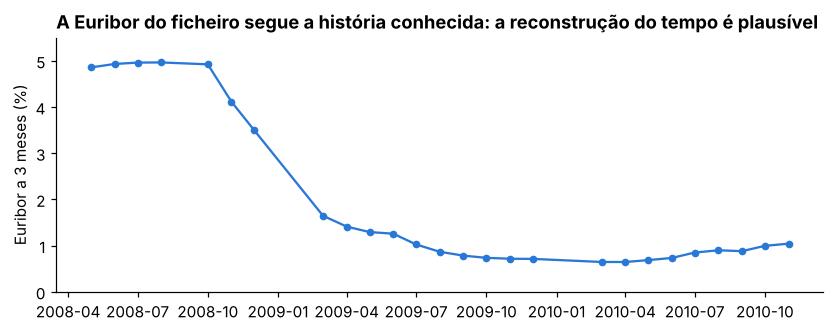

In [16]:
euribor = dados.groupby("periodo")["euribor_3m"].mean()

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(euribor.index, euribor.values, color=AZUL, marker="o", ms=4)
ax.set_ylim(0, 5.5)
ax.set_ylabel("Euribor a 3 meses (%)")
ax.set_title("A Euribor do ficheiro segue a história conhecida: a reconstrução do tempo é plausível")
plt.show()

A curva é a que se esperava. A reconstrução fica aceite, com a ressalva escrita.

### Enviesamento: quem está nos dados, e quando?

Com o tempo reconstruído, pode fazer-se a pergunta que mais importa numa auditoria: os dados representam sempre a mesma coisa?

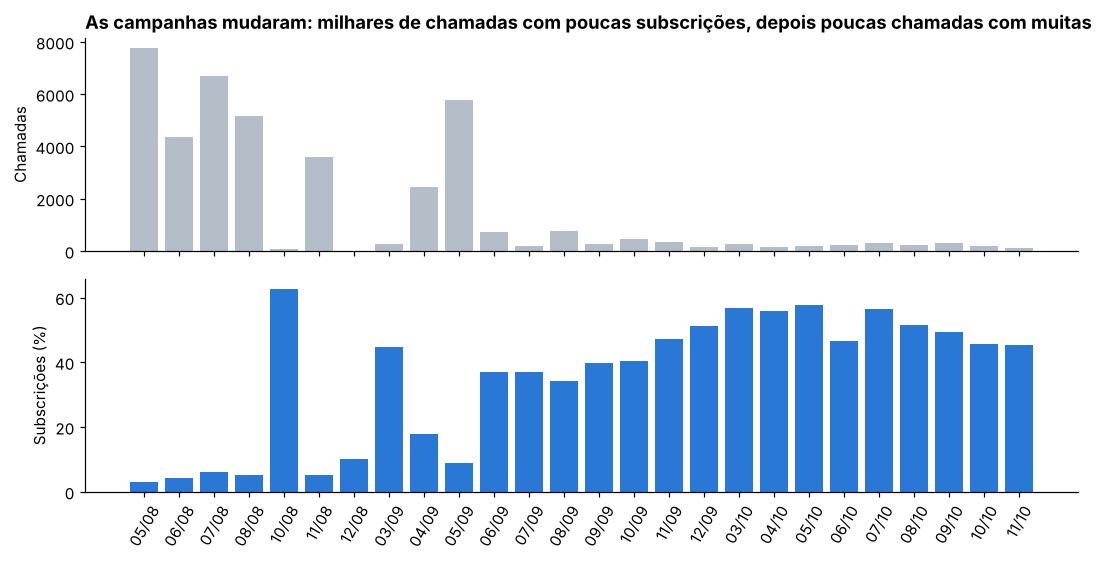

,chamadas,taxa
periodo,,
2008,27690,0.048
2009,11440,0.195
2010,2058,0.521


In [17]:
por_periodo = dados.assign(sim=dados["subscreveu"] == "yes").groupby("periodo").agg(chamadas=("sim", "size"), taxa=("sim", "mean"))
rotulos = [f"{p:%m/%y}" for p in por_periodo.index]

fig, (cima, baixo) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
cima.bar(rotulos, por_periodo["chamadas"], color=CINZA)
cima.set_ylabel("Chamadas")
cima.set_title("As campanhas mudaram: milhares de chamadas com poucas subscrições, depois poucas chamadas com muitas")
baixo.bar(rotulos, 100 * por_periodo["taxa"], color=AZUL)
baixo.set_ylabel("Subscrições (%)")
baixo.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

por_ano = dados.assign(sim=dados["subscreveu"] == "yes").groupby(dados["periodo"].dt.year).agg(chamadas=("sim", "size"), taxa=("sim", "mean"))
por_ano.round(3)

Esta é a figura mais importante da auditoria. O ficheiro não descreve um processo estável:

- Em **2008**, o banco fez campanhas em massa: mais de 27 000 chamadas, das quais cerca de 5% deram em subscrição.
- Em **2010**, fez cerca de 2 000 chamadas, e mais de metade deram em subscrição.

Os 11% do ficheiro inteiro são a média de duas realidades que não se parecem. A documentação não explica a mudança. Pode ser que o banco tenha passado a escolher melhor a quem telefona, que o produto tenha mudado, ou que a crise tenha tornado os depósitos mais atrativos. **Não se sabe**, e é preciso viver com isso.

O que se sabe é o que isto implica:

1. **Só há dados de quem o banco decidiu contactar**, e o critério de escolha mudou. Um modelo treinado aqui aprende sobre clientes contactados, e não sobre todos os clientes.
2. **Misturar as épocas ao acaso** em treino e teste daria a um modelo a oportunidade de adivinhar a época em vez de aprender sobre os clientes. A parte 2 mostra quanto isso engana.

## O que se pode usar no momento da previsão

Uma coluna do dicionário ficou marcada com «Não»: a duração da chamada.

In [18]:
dados.groupby("subscreveu")["duracao_s"].median()

subscreveu
no     163.5
yes    449.0
Name: duracao_s, dtype: float64

As chamadas que acabam em subscrição duram quase três vezes mais. Não admira: explicar e contratar um depósito demora. Mas a duração só se conhece **depois** de desligar, quando o resultado também já se conhece. Usá-la para decidir a quem telefonar é uma fuga de informação (módulo 4, capítulo 6): dá resultados excelentes no papel e é inútil na prática. A própria documentação avisa que esta coluna só deve servir para comparações de referência. Fica fora dos modelos.

Os cinco indicadores económicos são conhecidos antes da chamada, mas merecem desconfiança por outro motivo, que o exercício 2 esclarece.

## Guardar as decisões

Tudo o que foi decidido fica numa função, para que as partes 2 e 3 partam exatamente do mesmo ponto. É a regra do módulo 2: os dados em bruto não se alteram, e as correções fazem-se em código.

In [19]:
def preparar(bruto):
    """Aplica as decisões da parte 1: nomes em português, período reconstruído, alvo em 0 e 1, 999 como valor em falta."""
    t = bruto.rename(columns=NOMES)
    bloco = (t["mes"] != t["mes"].shift()).cumsum().to_numpy()
    assert bloco.max() == len(PERIODOS), "A sequência de meses não é a esperada."
    t["periodo"] = PERIODOS[bloco - 1]
    t["subscreveu"] = (t["subscreveu"] == "yes").astype(int)
    t["dias_desde_anterior"] = t["dias_desde_anterior"].replace(999, np.nan)
    return t


dados = preparar(bruto)
dados[["idade", "resultado_anterior", "dias_desde_anterior", "periodo", "subscreveu"]].tail(3)

,idade,resultado_anterior,dias_desde_anterior,periodo,subscreveu
41185,56,nonexistent,NaN,2010-11-01,0
41186,44,nonexistent,NaN,2010-11-01,1
41187,74,failure,NaN,2010-11-01,0


| Problema encontrado | Decisão | Tipo (módulo 2, cap. 4) |
| --- | --- | --- |
| Separador `;` | Ler com `sep=";"` | Normalizar |
| Nomes abreviados em inglês | Renomear, com dicionário de dados | Normalizar |
| `unknown` nas colunas de texto | Manter como categoria própria | Documentar |
| 999 em `dias_desde_anterior`, com dois significados | Trocar por valor em falta | Normalizar |
| 12 linhas repetidas, sem identificador | Manter | Documentar |
| Sem identificador de cliente | Limitação: o mesmo cliente pode repetir-se | Documentar |
| Sem ano | Reconstruir o período pela ordem das linhas; confirmado com a Euribor | Normalizar, com ressalva |
| Campanhas muito diferentes ao longo do tempo | Avaliar sempre no tempo; nunca misturar épocas | Documentar |
| `duracao_s` só se conhece depois da chamada | Excluir dos modelos | Documentar |
| Só clientes contactados | Limitação: as conclusões valem para quem o banco costuma contactar | Documentar |

## Exercícios

### `Exercício 1` – A falta que informa

Calcula a taxa de subscrição para cada valor de `incumprimento` (`no`, `unknown`, `yes`). Os clientes sem resposta subscrevem tanto como os outros? Que mecanismo de falta (módulo 4, capítulo 3) te parece mais provável, e o que implica para o tratamento da coluna?

In [20]:
# Escreve aqui o código do exercício 1

<details><summary><b>Ver uma solução possível</b></summary>

```python
dados.groupby("incumprimento")["subscreveu"].agg(clientes="size", taxa="mean").round(3)
```

Os clientes com `unknown` subscrevem cerca de 5% das vezes; os que têm `no`, cerca de 13%. A falta **não é ao acaso**: está associada ao alvo. Uma leitura plausível é que o banco não tem esta informação sobre clientes com quem tem menos relação, e que esses clientes também aderem menos.

A consequência prática é que **não se deve preencher** o `unknown` com a categoria mais frequente (`no`): apagaria um sinal útil. Mantê-lo como categoria própria, como foi decidido, é a opção certa. Repara ainda que os três clientes com `yes` não dão para concluir nada.

</details>

### `Exercício 2` – Indicadores económicos ou calendário?

Para cada um dos cinco indicadores económicos, conta quantos valores distintos existem **dentro de cada período**. O que concluis sobre a informação que estas colunas trazem?

In [21]:
# Escreve aqui o código do exercício 2

<details><summary><b>Ver uma solução possível</b></summary>

```python
economicos = ["var_emprego", "indice_precos", "indice_confianca", "euribor_3m", "n_empregados"]
dados.groupby("periodo")[economicos].nunique().max()
```

Quatro dos cinco indicadores têm **um único valor em cada mês**; só a Euribor, que é diária, varia dentro do mês. Isto quer dizer que estas colunas não dizem nada sobre o cliente: são uma forma de escrever a data. Todos os clientes contactados no mesmo mês têm os mesmos valores.

Um modelo que as use pode aprender «em novembro de 2009 subscrevia-se muito» e parecer excelente em dados dessa mesma época. Em campanhas futuras, com valores económicos que nunca viu, esse conhecimento não serve. A parte 2 mede o tamanho deste engano.

</details>

### `Exercício 3` – Uma coluna que parece inofensiva

A coluna `contactos_campanha` conta os contactos feitos ao cliente nesta campanha, **incluindo o atual**. Calcula a taxa de subscrição por número de contactos (1, 2, 3, 4 ou 5, 6 ou mais). Depois responde: esta coluna pode ser usada no momento da previsão? Com que cuidado?

In [22]:
# Escreve aqui o código do exercício 3

<details><summary><b>Ver uma solução possível</b></summary>

```python
escaloes = pd.cut(dados["contactos_campanha"], [0, 1, 2, 3, 5, 60], labels=["1", "2", "3", "4 ou 5", "6 ou mais"])
dados.groupby(escaloes, observed=True)["subscreveu"].agg(chamadas="size", taxa="mean").round(3)
```

A taxa desce com o número de contactos: quem ainda não aceitou à sexta chamada raramente aceita à sétima.

A coluna **conhece-se** antes de marcar o número (sabe-se quantas vezes já se ligou a este cliente), por isso pode ser usada. O cuidado é de interpretação: cada linha é o **último** contacto ao cliente na campanha, e as campanhas param quando o cliente aceita. Um cliente que aceitou à primeira aparece com 1; um que nunca aceitou aparece com o número total de tentativas. Parte da relação vem desta regra de paragem, e não de os contactos repetidos «causarem» recusas.

</details>

### `Exercício 4` – O que fica por saber

Escreve três perguntas que farias a alguém do banco antes de avançar, e diz o que mudaria no projeto com cada resposta.

<details><summary><b>Ver uma solução possível</b></summary>

1. **Como eram escolhidos os clientes de cada campanha, e o que mudou em 2009?** Se o banco passou a usar um critério (ou um modelo) para escolher, os dados de 2010 já são o resultado dessa escolha, e o novo modelo só aprende a ordenar dentro de um grupo já selecionado.
2. **A lista de 2010 vai parecer-se com a de 2008 ou com a de 2009?** Define que época deve servir de treino e de teste.
3. **As 12 linhas repetidas são erros de registo? Há um identificador de cliente que possa ser fornecido?** Com identificador, garantia-se que o mesmo cliente não fica no treino e no teste, e podia contar-se quantas vezes cada um foi contactado ao longo dos anos.

Outras perguntas válidas: que atributos foram retirados por privacidade; quanto custa uma chamada e quanto vale uma subscrição; os clientes deram consentimento para serem contactados.

</details>

## Verifica o que aprendeste

1. O resumo inicial mostrou zero valores em falta. Porque é que isso não quer dizer que os dados estão completos?
2. Que problema causa um valor sentinela como 999 numa média ou num modelo linear?
3. Como se reconstruiu o ano de cada linha, e que verificação independente foi feita?
4. Porque é que a taxa de subscrição do ficheiro inteiro (11%) é um número enganador?
5. Porque é que a duração da chamada fica fora dos modelos, apesar de ser a coluna mais associada ao alvo?

<details><summary><b>Ver respostas</b></summary>

1. Porque a falta está escrita de outra forma: `unknown` nas colunas de texto e 999 em `dias_desde_anterior`.
2. O valor inventado entra nas contas como se fosse uma medida: a média passa a 962 «dias», e um modelo linear trata 999 como um intervalo enorme, quando quer dizer «sem valor».
3. Pela ordem das linhas (a documentação diz que estão ordenadas por data) e pelas mudanças de mês, que formam 26 blocos. A verificação independente foi a Euribor, cuja evolução no ficheiro coincide com a história conhecida.
4. Porque é a média de épocas muito diferentes: cerca de 5% em 2008 e mais de 50% em 2010. Não descreve nenhuma delas.
5. Porque só se conhece depois da chamada, quando o resultado também já é conhecido. No momento de decidir a quem telefonar, não existe.

</details>

## Leitura recomendada

- S. Moro, P. Cortez e P. Rita (2014), *A Data-Driven Approach to Predict the Success of Bank Telemarketing*, Decision Support Systems, 62 — o artigo que descreve estes dados e o trabalho feito com a versão completa.
- Página do conjunto de dados no UCI Machine Learning Repository: https://doi.org/10.24432/C5K306
- Módulo 2, capítulo 4 (*Qualidade dos dados*) e módulo 4, capítulo 6 (*Pipelines sem fuga de informação*), para rever as ideias aplicadas aqui.

**A seguir:** na parte 2, exploras os dados, comparas duas formas de dividir em treino e teste, e descobres quanto um modelo consegue de facto acrescentar.